# Segmentação Semântica com dados sísmicos

Adaptado do artigo:

[A Machine Learning Benchmark for Facies Classification](https://arxiv.org/abs/1901.07659), por *Yazeed Alaudah, Patrycja Michalowicz, Motaz Alfarraj, Ghassan AlRegib*

In [6]:
# @title Importando bibliotecas / módulos
import collections
import numpy
import os
import PIL
import random
import torch
from tqdm.notebook import tqdm

torch.manual_seed(2025)

import matplotlib.pyplot as plt

## Netherlands F3 block

O bloco F3 da Holanda, no contexto do trabalho de Alaudah e colaboradores (referência necessária para o ano), é um conjunto de dados sísmicos 3D de alta qualidade e bem anotado, tornando-se um recurso valioso para pesquisadores que trabalham com interpretação sísmica e aprendizado de máquina.

Aqui estão alguns pontos-chave sobre o bloco F3 da Holanda usado por Alaudah e colaboradores:

*   Localização: Mar do Norte, Holanda
*   Data de aquisição: 1987 (pode ser um fator limitante devido à tecnologia de levantamento sísmico mais antiga)
*   Tipo de levantamento: Levantamento sísmico convencional (pode ter resolução inferior em comparação com levantamentos mais recentes)
*    Área de cobertura: Aproximadamente 384 quilômetros quadrados  
*    Resolução: Considerada alta para a época da aquisição
*    Anotação: Interpretações manuais de horizontes e falhas (permite o treinamento de modelos para tarefas de segmentação sísmica)
*     Disponibilidade pública: Sim (verifique a fonte original para detalhes de acesso)

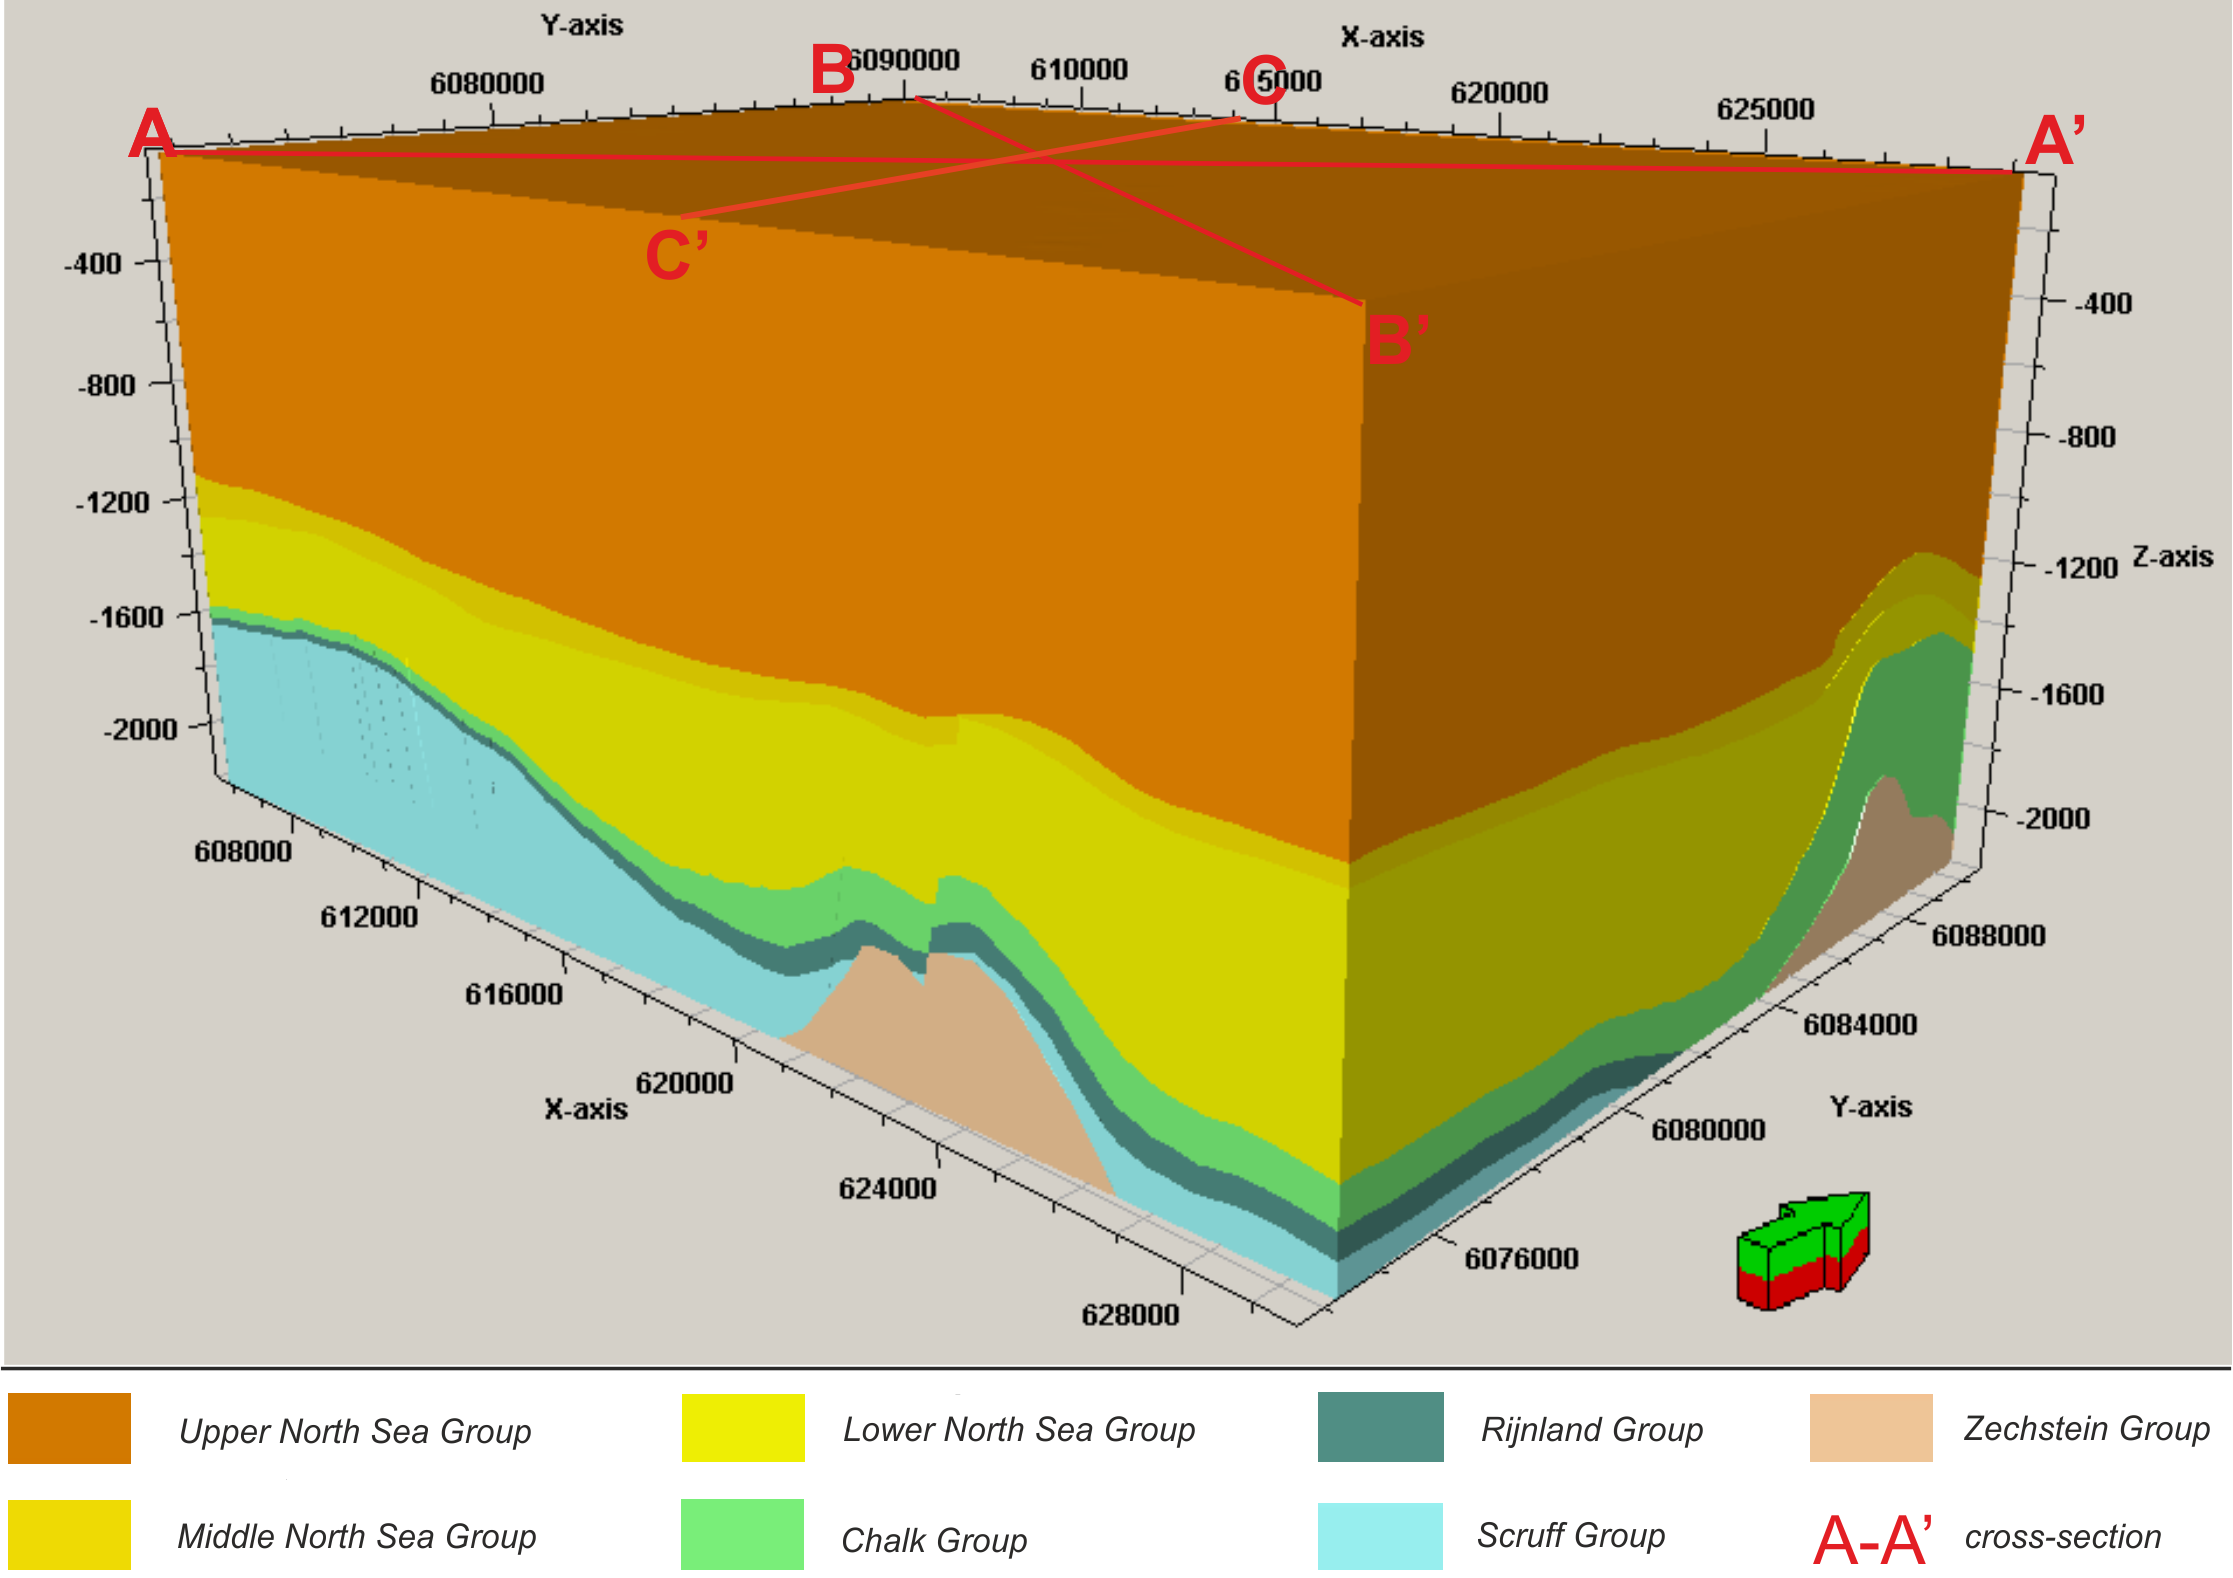


In [8]:
#@title Classe para base de dados
# https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataset
# https://pytorch.org/docs/stable/data.html#torch.utils.data.Dataloader
# https://pytorch.org/tutorials/beginner/basics/data_tutorial.html

class F3BlockDataset(torch.utils.data.Dataset):
    """
    Data loader for the section-based strategy for the NL dataset.

    Loads seismic and label data from the specified dataset split (train, valid, test1, or test2),
    optionally applies data augmentation, and transforms data into PyTorch tensors for training.
    Provides methods for decoding segmentation masks, accessing class information, and generating K-fold splits.
    """
    def __init__(self, split='train', subset=None, channel_delta=0, data_folder='data_NL', is_transform=True, augmentations=None):
        """
        Initializes the dataset.

        Args:
            split (str): Dataset split to load ('train', 'valid', 'test1', or 'test2').
            channel_delta (int): Number of adjacent channels to include in input data (0 or >0).
            data_folder (str): Path to the dataset directory.
            is_transform (bool): Whether to apply data normalization and channel expansions.
            augmentations (callable, optional): Augmentation function to apply to data.
        """
        self.split = split
        self.c_delta = channel_delta
        self.data_folder = data_folder
        self.is_transform = is_transform
        self.augmentations = augmentations
        self.n_classes = 6
        self.mean = 0.0009996710808862074
        self.stdev = 0.20976548783479299
        self.sections = collections.defaultdict(list)

        if self.split in ['train', 'valid', 'train_valid']:
            # Normal train/valid mode
            self.seismic = numpy.load(os.path.join(self.data_folder,'train','train_seismic.npy'))
            self.labels  = numpy.load(os.path.join(self.data_folder,'train','train_labels.npy'))
        elif self.split in ['test1']:
            self.seismic = numpy.load(os.path.join(self.data_folder,'test_once','test1_seismic.npy'))
            self.labels  = numpy.load(os.path.join(self.data_folder,'test_once','test1_labels.npy'))
        elif self.split in ['test2']:
            self.seismic = numpy.load(os.path.join(self.data_folder,'test_once','test2_seismic.npy'))
            self.labels  = numpy.load(os.path.join(self.data_folder,'test_once','test2_labels.npy'))
        else:
            raise ValueError(f'Unknown split: "{self.split}". Should be one of ["train", "valid", "train_val", "test1", "test2"]')

        if subset is None:
            irange, crange, depth = self.labels.shape
            i_list, c_list  = list(range(irange)), list(range(crange))
            i_list  = ['i_'+str(inline)    for inline    in i_list]
            c_list  = ['x_'+str(crossline) for crossline in c_list]
            self.sections[split] = i_list + c_list
        else:
            self.sections[split] = subset

    def __len__(self):
        """
        Returns the total number of sections in the dataset split.
        """
        return len(self.sections[self.split])

    def __getitem__(self, index):
        """
        Retrieves a single data sample (seismic image and label) at the specified index.

        Expected dataset shape: (401, 701, 255)
            "num_inlines": 401
            "num_crosslines": 701
            "num_time_depth": 255

        Args:
            index (int): Index of the sample to retrieve.

        Returns:
            tuple: A tuple containing the seismic image (torch.Tensor) and label mask (torch.Tensor).
        """
        section_name = self.sections[self.split][index]
        direction, number = section_name.split(sep='_')
        slice_number = int(number)

        if direction == 'i':
            try:
                lbl = self.labels[slice_number,:,:].transpose((1,0))
                if self.c_delta == 0:
                    img = self.seismic[slice_number,:,:].transpose((1,0))
                elif self.c_delta > 0:
                    img = self.seismic[max(0,slice_number-self.c_delta):min(self.seismic.shape[0],slice_number+self.c_delta+1),:,:]
                    img = numpy.stack([img[0,:,:], img[img.shape[0]//2,:,:], img[-1,:,:]]).transpose((0,2,1))
                else:
                    raise RuntimeError(f'INLINE - No implementation for self.c_delta={self.c_delta}')
            except:
                raise RuntimeError(f'INLINE - Batch {index}: \t section [{section_name}]={direction}_{slice_number} \t {self.seismic[slice_number,:,:].shape} {self.seismic[slice_number-self.c_delta:slice_number+self.c_delta+1,:,:].shape}')
        elif direction == 'x':
            try:
                lbl = self.labels[:,slice_number,:].transpose((1,0))
                if self.c_delta == 0:
                    img = self.seismic[:,slice_number,:].transpose((1,0))
                elif self.c_delta > 0:
                    img = self.seismic[:,max(0,slice_number-self.c_delta):min(self.seismic.shape[1],slice_number+self.c_delta+1),:]
                    img = numpy.stack([img[:,0,:], img[:,img.shape[1]//2,:], img[:,-1,:]]).transpose((0,2,1))
                else:
                    raise RuntimeError(f'CROSSLINE - No implementation for self.c_delta={self.c_delta}')
            except:
                raise RuntimeError(f'CROSSLINE - Batch {index}: \t section [{section_name}]={direction}_{slice_number} \t {self.seismic[:,slice_number,:].shape} {self.seismic[:,slice_number-self.c_delta:slice_number+self.c_delta+1,:].shape}')
        else:
            raise RuntimeError(f'Seismic direction does not correspond to INLINE (I) or CROSSLINE (X)')

        if self.augmentations is not None:
            img, lbl = self.augmentations(img, lbl)

        if self.is_transform:
            img, lbl = self.transform(img, lbl)
        return img, lbl

    def decode_segmap(self, label_mask, plot=False, save_name=None):
        """
        Decodes a segmentation label mask into a color image.

        Args:
            label_mask (numpy.ndarray): An array of integer class labels.
            plot (bool, optional): Whether to display the decoded image.
            save_name (str, optional): Name to save the decoded image if provided.

        Returns:
            numpy.ndarray: The decoded color image array, or None if plot=True.
        """
        label_colours = self.get_seismic_colors()
        r = label_mask.copy()
        g = label_mask.copy()
        b = label_mask.copy()
        for ll in range(0, self.n_classes):
            r[label_mask == ll] = label_colours[ll, 0]
            g[label_mask == ll] = label_colours[ll, 1]
            b[label_mask == ll] = label_colours[ll, 2]
        rgb = numpy.zeros((label_mask.shape[0], label_mask.shape[1], 3))
        rgb[:, :, 0] = r / 255.0
        rgb[:, :, 1] = g / 255.0
        rgb[:, :, 2] = b / 255.0
        plt.tight_layout()
        if save_name is not None:
            plt.imshow(rgb)
            plt.savefig(save_name)
        if plot:
            plt.imshow(rgb)
            plt.show()
        else:
            return rgb

    def transform(self, img, lbl):
        """
        Applies data normalization and channel expansions to prepare data for PyTorch.

        Args:
            img (numpy.ndarray): Image data.
            lbl (numpy.ndarray): Label data.

        Returns:
            img (torch.Tensor): Transformed image data.
            lbl (torch.Tensor): Transformed label data.
        """
        img = (img - self.mean)/self.stdev

        # to be in the BxCxHxW that PyTorch uses:
        if len(img.shape) == 2:
            img = numpy.expand_dims(img,0)
        if len(lbl.shape) == 2:
            lbl = numpy.expand_dims(lbl,0)

        img = torch.from_numpy(img).float()
        lbl = torch.from_numpy(lbl).long()

        return img, lbl

    def get_class_names(self):
        """
        Returns a list of class names corresponding to the segmentation labels.
        """
        return ['upper_ns', 'middle_ns', 'lower_ns', 'rijnland_chalk', 'scruff', 'zechstein']

    def get_class_weights(self):
        """
        Returns a list of class weights, potentially for addressing class imbalance.
        Alaudah paper: [0.7151, 0.8811, 0.5156, 0.9346, 0.9683, 0.9852]
        """
        bin_count = numpy.bincount(self.labels.flatten())
        return 1. - (bin_count / numpy.sum(bin_count))

    def get_prediction_horizons(self):
        """
        Returns a list of depth indices for prediction horizons.
        """
        return [0, 99, 149, 299, 399, 499]

    def get_seismic_colors(self):
        """
        Returns an array of RGB color codes for visualizing seismic data.
        """
        return numpy.asarray([ [69,117,180], [145,191,219], [224,243,248], [254,224,144], [252,141,89], [215,48,39]])

    @staticmethod
    def split_train_val(data_folder, loader_type='section', per_val=0.1):
        """
            Splits inline and crossline sections for training and validation.

            This function splits inline and crossline sections from a seismic dataset for
            training and validation purposes. It accepts various arguments to control the
            splitting process:

            Args:
                data_folder (str): Path to the data folder containing the dataset.
                loader_type (str, optional): Type of loader to be used ('section' or 'horizon'). Defaults to 'section'.
                per_val (float, optional): Proportion of data to be used for validation. Defaults to 0.1.

            Returns:
                None

            Raises:
                ValueError: If `loader_type` is not 'section' or 'horizon'.

            Saves:
                - Three text files in the `data_folder/splits` directory:
                    - `loader_type_train_val.txt`: List of all sections for both training and validation.
                    - `loader_type_train.txt`: List of sections used for training.
                    - `loader_type_val.txt`: List of sections used for validation.
        """
        from sklearn.model_selection import train_test_split
        labels = numpy.load(os.path.join(data_folder, 'train', 'train_labels.npy'))
        irange, crange, depth = labels.shape

        i_list = list(range(irange))
        i_list = ['i_'+str(inline) for inline in i_list]

        c_list = list(range(crange))
        c_list = ['x_'+str(crossline) for crossline in c_list]

        # create train and validation splits:
        list_train_i, list_valid_i = train_test_split(i_list, test_size=per_val, shuffle=False, random_state=0)
        list_train_c, list_valid_c = train_test_split(c_list, test_size=per_val, shuffle=False, random_state=0)

        return (list_train_i + list_train_c, list_valid_i + list_valid_c)

## Exercício 1

Dadas as classes definidas acima, preencha os células abaixo, instanciando objetos da seguinte maneira:

* Separe o conjunto de treinamento em dois subconjuntos disjuntos (treino com 90% dos dados e validação com o restante 10%).
* Crie objetos da classe `F3BlockDataset` para os subconjuntos de treino e validação. Forneça somente os paramêtros `split`, `subset`, e `data_folder`. Não utilizaremos *data augmentation* por enquanto.
* Crie o gerenciador de *batches* (`torch.utils.data.DataLoader`) para que as amostras de sua base de dados possam ser devidamente carregadas.

In [9]:
# @title Separando Treino e Validação


# Na Tatu, os dados já estão salvos no seguinte diretório:
data_path = '/pgeoprj2/ciag2024/dados/f3'

train_subset, valid_subset = F3BlockDataset.split_train_val(data_folder=data_path, per_val=0.1)

In [10]:
# @title Definindo seus Datasets

# TODO: Defina os datasets de treino e validação baseados nos subsets obtidos
train_dataset = F3BlockDataset(split='train', subset=train_subset, channel_delta=0, data_folder=data_path, is_transform=True)
valid_dataset = F3BlockDataset(split='valid', subset=valid_subset, channel_delta=0, data_folder=data_path, is_transform=True)

In [11]:
#@title Definindo o carregador do Dataset
class CustomSampler(torch.utils.data.Sampler):
    def __init__(self, sample_list):
        self.counter = 0
        self.sample_list = sample_list

    def __iter__(self):
        mode = 'i' if (self.counter % 2 == 0) else 'x'
        self.counter += 1
        self.indices = [idx for (idx, name) in enumerate(self.sample_list) if mode in name]
        return (self.indices[i] for i in torch.randperm(len(self.indices)))

    def __len__(self):
        mode = 'i' if (self.counter % 2 == 0) else 'x'
        indices = [idx for (idx, name) in enumerate(self.sample_list) if mode in name]
        return len(indices)

# https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader
# TODO: crie os dataloaders de treino e validação
train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=4, sampler=CustomSampler(train_subset), num_workers=0, shuffle=False)
valid_dataloader = torch.utils.data.DataLoader(valid_dataset, batch_size=4, sampler=CustomSampler(valid_subset), num_workers=0)

## DeconvNet: Deconvolutional Network

DeconvNet, também conhecido como rede deconvolucional, é uma arquitetura de rede neural artificial (RNA) inspirada na rede convolucional (CNN). Enquanto as CNNs são usadas para extrair recursos de imagens e realizar tarefas como classificação e reconhecimento de objetos, as DeconvNets são usadas para gerar imagens a partir de representações de alto nível.

As DeconvNets invertem o processo de convolução usado em CNNs. Em vez de usar filtros convolucionais para reduzir a dimensionalidade das entradas, as DeconvNets usam filtros de deconvolução para aumentar a dimensionalidade das entradas. Isso significa que elas podem transformar representações compactas de alto nível em imagens com alta resolução espacial.

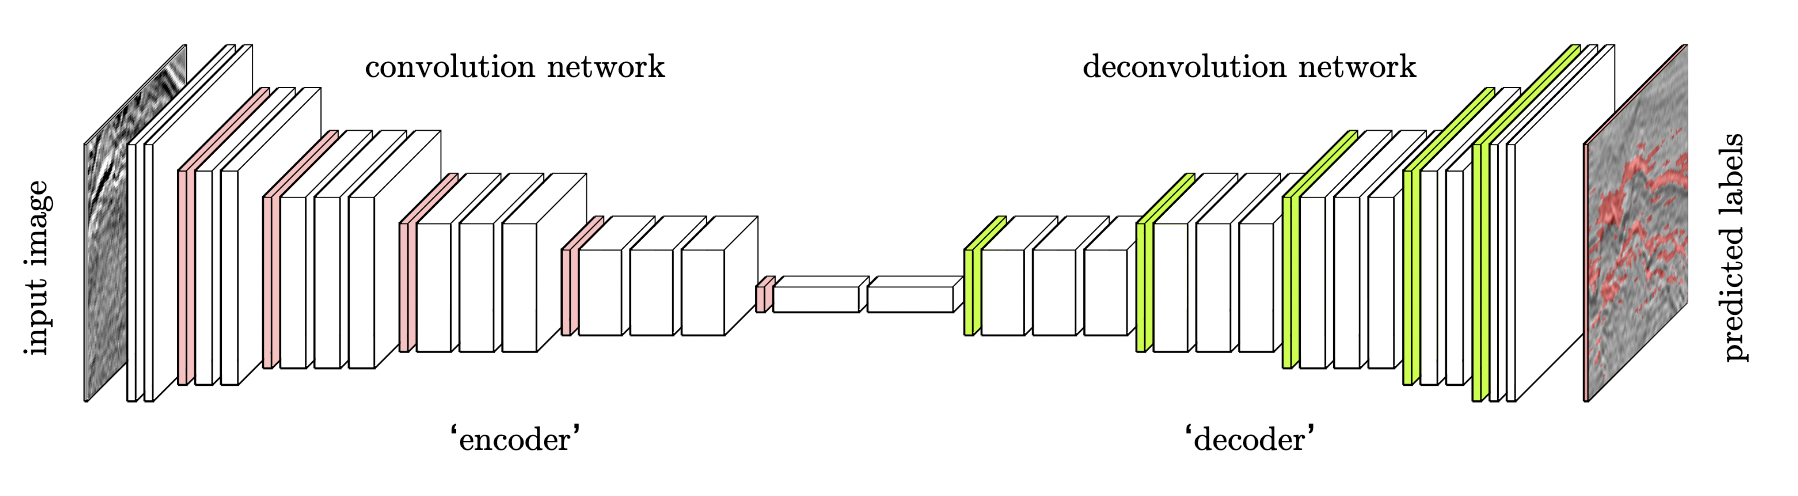

In [ ]:
class ConvBlock(torch.nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, padding=1):
        super(ConvBlock, self).__init__()
        self.conv = torch.nn.Conv2d(in_channels, out_channels, kernel_size=kernel_size, padding=padding)
        self.bn = torch.nn.BatchNorm2d(out_channels)
        self.relu = torch.nn.ReLU()

    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))
    
class DeconvBlock(torch.nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, padding=1):
        super(DeconvBlock, self).__init__()
        self.deconv = torch.nn.ConvTranspose2d(in_channels, out_channels, kernel_size=kernel_size, padding=padding)
        self.bn = torch.nn.BatchNorm2d(out_channels)
        self.relu = torch.nn.ReLU()

    def forward(self, x):
        return self.relu(self.bn(self.deconv(x)))

In [12]:
class DeconvNet(torch.nn.Module):
    """
    DeconvNet model for semantic segmentation, inspired by VGG16 architecture.

    It consists of a contracting path (similar to VGG16) followed by an
    expanding path with unpooling and deconvolution layers.
    """

    def __init__(self, n_channels=1, n_classes=6):
        """
        Initializes the DeconvNet model.

        Args:
            n_channels (int, optional): Number of input channels (default: 1).
            n_classes (int, optional): Number of output classes (default: 6).
        """
        super(DeconvNet, self).__init__()
        self.n_classes = n_classes
        self.pool = torch.nn.MaxPool2d(
            2, stride=2, return_indices=True, ceil_mode=True
        )
        self.unpool = torch.nn.MaxUnpool2d(2, stride=2)

        ### Contracting path (similar to VGG16) ###

        self.conv_block1 = torch.nn.Sequential(
            # conv1_1
            ConvBlock(n_channels, 64),
            # conv1_2
            ConvBlock(64, 64),
        )

        # 48*48
        self.conv_block2 = torch.nn.Sequential(
            # conv2_1
            ConvBlock(64, 128),
            # conv2_2
            ConvBlock(128, 128),
        )

        # 24*24
        self.conv_block3 = torch.nn.Sequential(
            # conv3_1
            ConvBlock(128, 256),
            # conv3_2
            ConvBlock(256, 256),
            # conv3_3
            ConvBlock(256, 256),
        )

        # 12*12
        self.conv_block4 = torch.nn.Sequential(
            # conv4_1
            ConvBlock(256, 512),
            # conv4_2
            ConvBlock(512, 512),
            # conv4_3
            ConvBlock(512, 512),
        )

        # 6*6
        self.conv_block5 = torch.nn.Sequential(
            # conv5_1
            ConvBlock(512, 512),
            # conv5_2
            ConvBlock(512, 512),
            # conv5_3
            ConvBlock(512, 512),
        )

        # 3*3
        self.conv_block6 = torch.nn.Sequential(
            # fc6
            # set the filter size and nor padding to make output into 1*1
            ConvBlock(512, 4096, kernel_size=3, padding=0),
        )

        # 1*1
        self.conv_block7 = torch.nn.Sequential(
            # fc7
            # set the filter size to make output into 1*1
            ConvBlock(4096, 4096, kernel_size=1, padding=0),
        )

        ### Expanding path ###

        self.deconv_block6 = torch.nn.Sequential(
            # fc6-deconv
            DeconvBlock(4096, 512, kernel_size=3, padding=0),
        )

        # 6*6
        self.deconv_block5 = torch.nn.Sequential(
            # deconv5_1
            DeconvBlock(512, 512),
            # deconv5_2
            DeconvBlock(512, 512),
            # deconv5_3
            DeconvBlock(512, 512),
        )

        # 12*12
        self.deconv_block4 = torch.nn.Sequential(
            # deconv4_1
            DeconvBlock(512, 512),
            # deconv4_2
            DeconvBlock(512, 512),
            # deconv4_3
            DeconvBlock(512, 256),
        )

        # 24*24
        self.deconv_block3 = torch.nn.Sequential(
            # deconv3_1
            DeconvBlock(256, 256),
            # deconv3_2
            DeconvBlock(256, 256),
            # deconv3_3
            DeconvBlock(256, 128),
        )

        # 48*48
        self.deconv_block2 = torch.nn.Sequential(
            # deconv2_1
            DeconvBlock(128, 128),
            # deconv2_2
            DeconvBlock(128, 64),
        )

        # 96*96
        self.deconv_block1 = torch.nn.Sequential(
            # deconv1_1
            DeconvBlock(64, 64),
            # deconv1_2
            DeconvBlock(64, 64),
        )

        ### Final segmentation layer ###

        self.seg_score19 = torch.nn.Sequential(
            # seg-score
            torch.nn.Conv2d(64, self.n_classes, kernel_size=1),
        )

    def forward(self, x):
        """
        Forward pass of the DeconvNet model.

        Args:
            x (torch.Tensor): Input tensor of shape (N, C, H, W).

        Returns:
            torch.Tensor: Output tensor of shape (N, n_classes, H, W) containing segmentation predictions.
        """
        size0 = x.size()
        # Contracting path
        conv1, indices1 = self.pool(self.conv_block1(x))
        size1 = conv1.size()
        conv2, indices2 = self.pool(self.conv_block2(conv1))
        size2 = conv2.size()
        conv3, indices3 = self.pool(self.conv_block3(conv2))
        size3 = conv3.size()
        conv4, indices4 = self.pool(self.conv_block4(conv3))
        size4 = conv4.size()
        conv5, indices5 = self.pool(self.conv_block5(conv4))
        conv6 = self.conv_block6(conv5)
        conv7 = self.conv_block7(conv6)
        # Expanding path
        deconv6 = self.deconv_block6(conv7)
        deconv5 = self.unpool(deconv6, indices5, output_size=size4)
        deconv5 = self.deconv_block5(deconv5)
        deconv4 = self.unpool(deconv5, indices4, output_size=size3)
        deconv4 = self.deconv_block4(deconv4)
        deconv3 = self.unpool(deconv4, indices3, output_size=size2)
        deconv3 = self.deconv_block3(deconv3)
        deconv2 = self.unpool(deconv3, indices2, output_size=size1)
        deconv2 = self.deconv_block2(deconv2)
        deconv1 = self.unpool(deconv2, indices1, output_size=size0)
        deconv1 = self.deconv_block1(deconv1)
        # Final segmentation layer
        out = self.seg_score19(deconv1)
        return out

A convolução transposta, também conhecida como deconvolução ou upsampling convolucional, é uma operação fundamental em redes neurais convolucionais (CNNs) que permite aumentar a dimensão espacial de um mapa de feições. Em contraste com a convolução padrão, que reduz a dimensão espacial, a convolução transposta gera um mapa de saída com maior largura, altura ou ambas.

A convolução transposta é utilizada em diversas aplicações de aprendizado de máquina, incluindo:
* Upsampling de imagens: Permite aumentar a resolução espacial de imagens de baixa resolução, como em tarefas de geração de imagens, super-resolução e segmentação semântica.
* Síntese de imagens: Gera imagens a partir de representações de alto nível, como em tarefas de geração de imagens e tradução de estilo.
* Visualização de mapas de feições: Permite visualizar mapas de feições gerados por CNNs em alta resolução, facilitando a interpretação dos resultados.


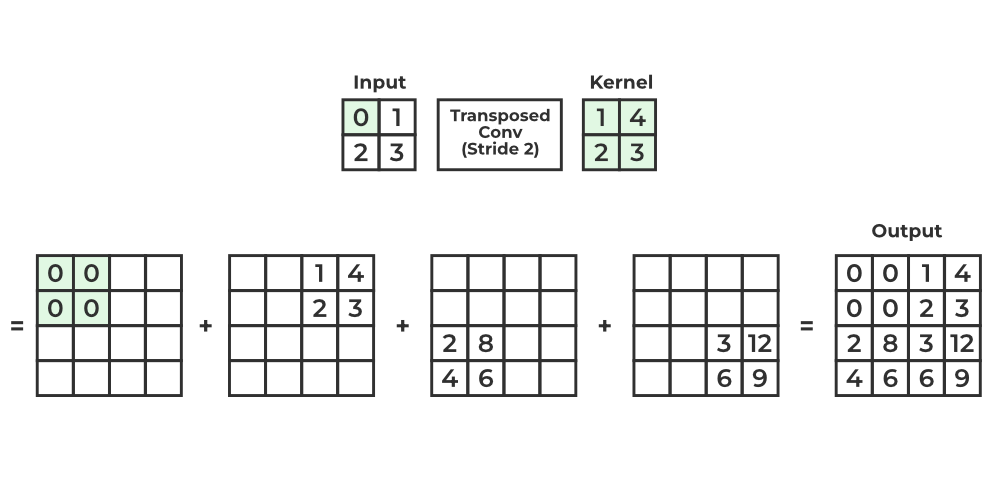

## Exercício 2

* Agora com sua arquitetura `DeconvNet` definida, crie um objeto especificando corretamente o número de canais de entrada e o número de classes.
* Instancie a função de custo baseada em entropia cruzada, podendo ser a `torch.nn.CrossEntropyLoss` ou sua versão modificada para segmentação `CrossEntropyLoss` definida abaixo. Varie entre `reduction=sum` ou `reduction=mean` e veja a diferença durante o treinamento.
* Instancie seu otimizador, escolhendo entre `torch.optim.Adam` ou `torch.optim.SGD`. Fique atento quanto aos parâmetros de cada um.

In [13]:
#@title Criando rede DeconvNet

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# TODO: defina a rede DeconvNet
network = DeconvNet(n_channels=1, n_classes=train_dataset.n_classes).to(device)

In [14]:
#@title Definindo Perca e Otimizador
class CrossEntropyLoss:
    def __init__(self, ignore_index=255, reduction='none', weight=None):
        self.ignore_index = ignore_index
        self.reduction = reduction
        self.weight = weight

    def __call__(self, slices, targets):
        if len(targets.shape) > 3:
            targets = torch.squeeze(targets, dim=1)
        return torch.nn.functional.cross_entropy(slices, targets, ignore_index=self.ignore_index, reduction=self.reduction, weight=self.weight)


# https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html
# https://pytorch.org/docs/stable/generated/torch.optim.Adadelta.html
# https://pytorch.org/docs/stable/generated/torch.optim.Adam.html
# https://pytorch.org/docs/stable/generated/torch.optim.SGD.html
# TODO: defina a perda e o otimizador
criterion = CrossEntropyLoss(reduction='sum', weight=None)
optimizer = torch.optim.Adadelta(network.parameters())
# optimizer = torch.optim.Adam(network.parameters(), lr=3e-4, amsgrad=True)
# optimizer = torch.optim.SGD(network.parameters(), lr=3e-4)

## Treinamento e Validação

In [15]:
#@title Definindo Métricas
class RunningScore:
    def __init__(self, n_classes):
        self.confusion_matrix = torch.zeros((n_classes, n_classes))
        self.n_classes = n_classes

    def __compute_matrix(self, label_true, label_pred, n_class):
        mask = (label_true >= 0) & (label_true < n_class)
        hist = torch.bincount(n_class * label_true[mask].to(int) + label_pred[mask], minlength=n_class**2).reshape(n_class, n_class)
        return hist.cpu()

    def update(self, slices, targets):
        label_preds, label_trues = slices.detach().max(dim=1)[1], targets.detach()
        for lp, lt in zip(label_preds, label_trues):
            self.confusion_matrix += self.__compute_matrix(lt.flatten(), lp.flatten(), self.n_classes)

    def get_scores(self, epoch=None):
        """
        Returns accuracy score evaluation result.
            - overall accuracy
            - mean accuracy
            - mean IU
        """
        hist = self.confusion_matrix
        acc = torch.diag(hist).sum() / hist.sum()
        acc_cls = torch.diag(hist) / hist.sum(dim=1)
        mean_acc_cls = torch.nanmean(acc_cls)
        iu = torch.diag(hist) / (hist.sum(dim=0) + hist.sum(dim=1) - torch.diag(hist))
        mean_iu = torch.nanmean(iu)
        cls_iu = dict(zip(range(self.n_classes), iu))
        return {'Pixel Acc': acc.item(),
                'Class Accuracy': acc_cls.tolist(),
                'Mean Class Acc': mean_acc_cls.item(),
                'Mean IoU': mean_iu.item(),
                'Confusion Matrix': self.confusion_matrix.tolist()}

    def reset(self):
        self.confusion_matrix = torch.zeros(size=(self.n_classes, self.n_classes))

In [16]:
#@title Treino em uma única época
def train_single_epoch(train_dataloader, criterion, optimizer, network, device='cpu', metrics=None):
    statistics, training_loss = None, 0.

    network.train()
    for batch, (images, labels) in enumerate(train_dataloader):
        optimizer.zero_grad()

        images, labels = images.to(device), labels.to(device)
        outputs = network(images)

        if metrics is not None:
            metrics.update(slices=outputs, targets=labels)

        loss = criterion(slices=outputs, targets=labels)
        training_loss += loss.item() / len(images)
        loss.backward()
        optimizer.step()

        # print segmentation on training data
        print(f'TRAINING - Batch: {batch + 1} | Loss: {training_loss / (batch + 1)}')

        # display segmentation on training data
        out_figure = {
            'Image': images[0].detach().cpu().numpy().squeeze(),
            'Preds': train_dataloader.dataset.decode_segmap(outputs[0].detach().cpu().argmax(dim=0).numpy()),
            'Label': train_dataloader.dataset.decode_segmap(labels[0].detach().cpu().numpy().squeeze())
        }
        figure, axes = plt.subplots(1, 3, figsize=(12, 3))
        for axis,(segname,segmap) in zip(axes, out_figure.items()):
            axis.set_title(segname)
            axis.imshow(segmap)
        plt.show()
        plt.close()

        if (batch + 1) % 5 == 0:
            break

    # reset epoch statistics
    if metrics is not None:
        statistics = metrics.get_scores()
        metrics.reset()

    return network, statistics

TRAINING - Batch: 1 | Loss: 333771.6875


<Figure size 640x480 with 0 Axes>

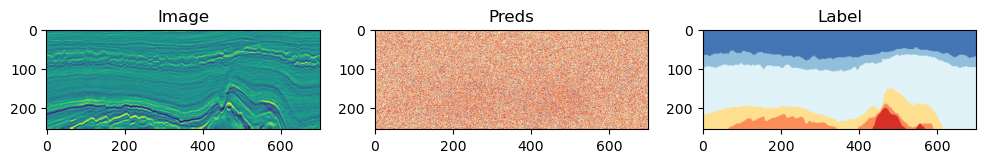

TRAINING - Batch: 2 | Loss: 327459.671875


<Figure size 640x480 with 0 Axes>

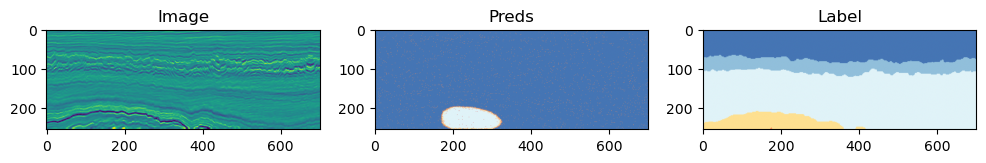

TRAINING - Batch: 3 | Loss: 322946.3645833333


<Figure size 640x480 with 0 Axes>

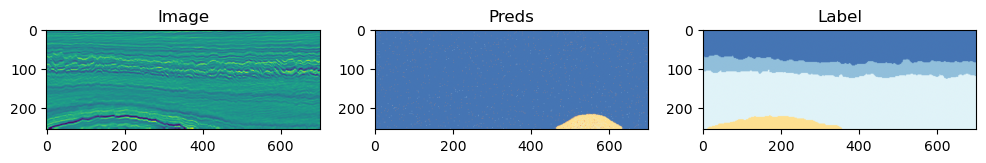

TRAINING - Batch: 4 | Loss: 320504.9375


<Figure size 640x480 with 0 Axes>

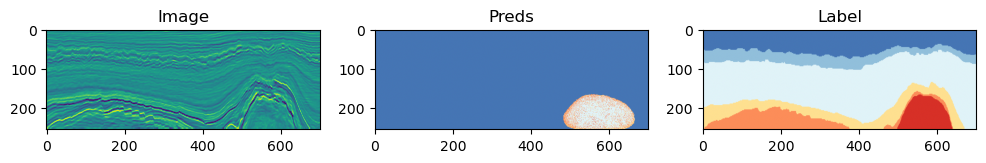

TRAINING - Batch: 5 | Loss: 316734.95625


<Figure size 640x480 with 0 Axes>

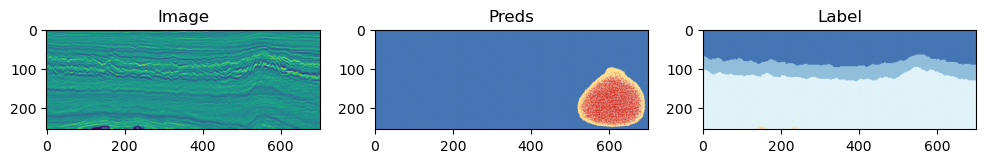

Statistics
	Pixel Acc: 0.26319822669029236
	Class Accuracy: [0.8204551935195923, 0.009298753924667835, 0.048990026116371155, 0.08611223846673965, 0.12649540603160858, 0.04858110472559929]
	Mean Class Acc: 0.18998879194259644
	Mean IoU: 0.07328235357999802
	Confusion Matrix: [[811696.0, 8122.0, 35463.0, 55031.0, 44791.0, 34221.0], [335928.0, 3887.0, 19691.0, 22675.0, 21151.0, 14681.0], [1331114.0, 17349.0, 85000.0, 105124.0, 118096.0, 78364.0], [169614.0, 3281.0, 25522.0, 22084.0, 24445.0, 11510.0], [72072.0, 2463.0, 10749.0, 15095.0, 15797.0, 8706.0], [18755.0, 785.0, 14284.0, 4095.0, 10963.0, 2496.0]]


In [17]:
training_score = RunningScore(n_classes=train_dataset.n_classes)
network, statistics = train_single_epoch(train_dataloader, criterion, optimizer, network, device=device, metrics=training_score)

print('Statistics')
for key, value in statistics.items():
    print(f'\t{key}: {value}')

## Exercício 3

Dado que você tem o treinamento em uma única época na célula acima, implemente uma função que realize o treinamento e a validação, de acordo com os parâmetros abaixo:
* `train_dataloader`: gerenciador de dados do subconjunto de treinamento
* `valid_dataloader`: gerenciador de dados do subconjunto de validação
* `criterion`: função de custo
* `optimizer`: otimizador
* `network`: modelo contendo a arquitetura escolhida
* `device`: dispositivo onde o modelo será treinado (cpu ou cuda)
* `num_epochs`: número de épocas durante o treinamento
* `visual`: parâmetro boleano indicando exibição dos gráficos

In [18]:
#@title Definindo Treino e Validação
def train_valid_stage(train_dataloader, valid_dataloader, criterion, optimizer, network, device='cpu', num_epochs=10, visual=False):
    # TODO: implementar treino e validação
    train_metrics = RunningScore(n_classes=train_dataloader.dataset.n_classes)
    valid_metrics = RunningScore(n_classes=train_dataloader.dataset.n_classes)
    valid_mIoU = 0.

    for epoch in range(num_epochs):
        # training step
        network.train()
        training_loss = 0.
        train_dataloader.sampler.counter = 0
        for batch, (images, labels) in tqdm(enumerate(train_dataloader), total=len(train_dataloader), unit='batches'):
            optimizer.zero_grad()

            images, labels = images.to(device), labels.to(device)
            outputs = network(images)

            train_metrics.update(slices=outputs, targets=labels)

            loss = criterion(slices=outputs, targets=labels)
            training_loss += loss.item() / len(images)
            loss.backward()
            optimizer.step()

        print(f'TRAINING - Epoch: {epoch + 1} | Loss: {training_loss / (batch + 1)}')
        if visual:
            # display segmentation on training data
            figure, axes = plt.subplots(1, 3, figsize=(12, 3))
            out_figure = {
                'Image': images[0].detach().cpu().numpy().squeeze(),
                'Preds': train_dataloader.dataset.decode_segmap(outputs[0].detach().cpu().argmax(dim=0).numpy()),
                'Label': train_dataloader.dataset.decode_segmap(labels[0].detach().cpu().numpy().squeeze())
            }
            for axis,(segname,segmap) in zip(axes, out_figure.items()):
                axis.set_title(segname)
                axis.imshow(segmap)
            plt.show()
            plt.close()

        train_statistics = train_metrics.get_scores()
        for (key, value) in train_statistics.items():
            print(f'\t{key}: {value}')
        train_metrics.reset()


        # validation step
        network.eval()
        validation_loss = 0.
        for batch, (images, labels) in enumerate(valid_dataloader):
            images, labels = images.to(device), labels.to(device)
            outputs = network(images)

            valid_metrics.update(slices=outputs, targets=labels)

            loss = criterion(slices=outputs, targets=labels)
            training_loss += loss.item() / len(images)

        print(f'VALIDATION - Epoch: {epoch + 1} | Loss: {training_loss / (batch + 1)}')
        if visual:
            # display segmentation on training data
            figure, axes = plt.subplots(1, 3, figsize=(12, 3))
            out_figure = {
                'Image': images[0].detach().cpu().numpy().squeeze(),
                'Output': train_dataloader.dataset.decode_segmap(outputs[0].detach().cpu().argmax(dim=0).numpy()),
                'Label': train_dataloader.dataset.decode_segmap(labels[0].detach().cpu().numpy().squeeze())
            }
            for axis,(segname,segmap) in zip(axes, out_figure.items()):
                axis.set_title(segname)
                axis.imshow(segmap)
            plt.show()
            plt.close()

        valid_statistics = valid_metrics.get_scores()
        if valid_statistics['Mean IoU'] > valid_mIoU:
            torch.save(network.state_dict(), 'model.pth')
        for (key,value) in valid_statistics.items():
            print(f'\t{key}: {value}')
        valid_metrics.reset()

    return network, valid_statistics

  0%|          | 0/90 [00:00<?, ?batches/s]

TRAINING - Epoch: 1 | Loss: 144116.4070746528


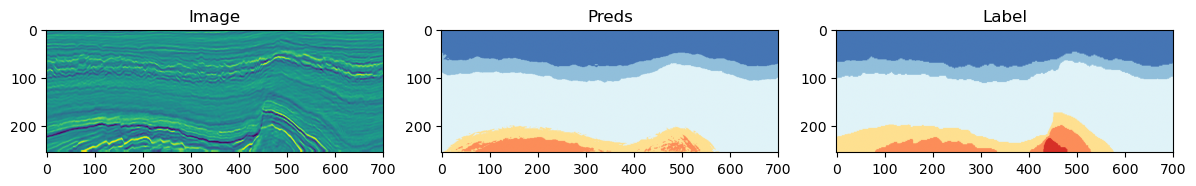

	Pixel Acc: 0.7098844647407532
	Class Accuracy: [0.9055573344230652, 0.30745211243629456, 0.8131318092346191, 0.2781020402908325, 0.3164759576320648, 2.116569157806225e-05]
	Mean Class Acc: 0.4367900788784027
	Mean IoU: 0.3307378888130188
	Confusion Matrix: [[16066210.0, 469233.0, 1205685.0, 39.0, 160.0, 464.0], [2839406.0, 2305568.0, 2341578.0, 11094.0, 1109.0, 195.0], [3754023.0, 917833.0, 25277972.0, 748396.0, 362592.0, 26361.0], [444819.0, 66960.0, 2435379.0, 1288815.0, 391328.0, 7023.0], [222006.0, 27707.0, 837079.0, 517147.0, 743766.0, 2445.0], [87637.0, 11040.0, 391404.0, 249078.0, 300237.0, 22.0]]
VALIDATION - Epoch: 1 | Loss: 1324654.4754971592


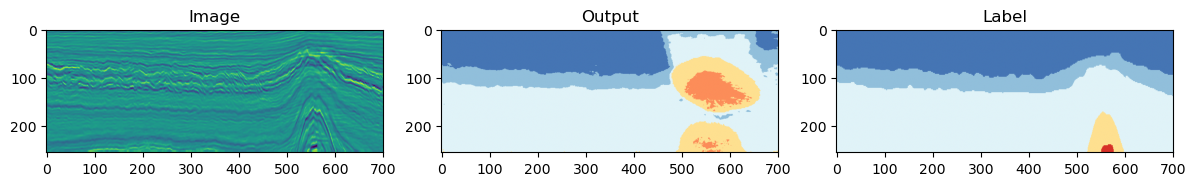

	Pixel Acc: 0.7593581676483154
	Class Accuracy: [0.7140387296676636, 0.5655324459075928, 0.8553508520126343, 0.5914245247840881, nan, 0.0]
	Mean Class Acc: 0.5452693104743958
	Mean IoU: 0.3298303782939911
	Confusion Matrix: [[1710871.0, 322504.0, 361236.0, 1437.0, 0.0, 0.0], [4864.0, 577248.0, 279788.0, 157669.0, 1147.0, 0.0], [0.0, 15871.0, 3202395.0, 309361.0, 216328.0, 0.0], [0.0, 625.0, 45798.0, 74788.0, 5243.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 597.0, 32546.0, 8639.0, 0.0]]


  0%|          | 0/90 [00:00<?, ?batches/s]

TRAINING - Epoch: 2 | Loss: 47326.64835069444


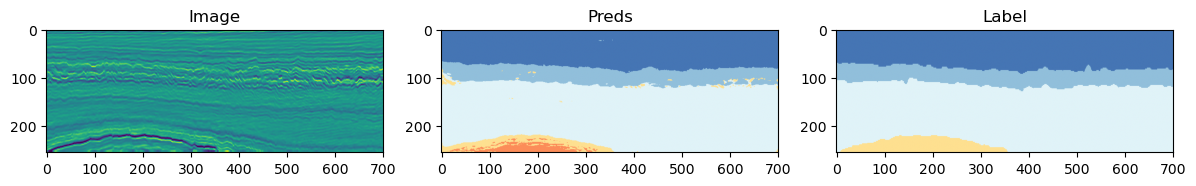

	Pixel Acc: 0.9033317565917969
	Class Accuracy: [0.9743766784667969, 0.8606891632080078, 0.9411293268203735, 0.7242929339408875, 0.7540263533592224, 0.0037011096719652414]
	Mean Class Acc: 0.7097025513648987
	Mean IoU: 0.5987036824226379
	Confusion Matrix: [[17287184.0, 423416.0, 15454.0, 14922.0, 813.0, 0.0], [437232.0, 6454265.0, 570753.0, 30315.0, 6385.0, 0.0], [14558.0, 709854.0, 29257044.0, 947630.0, 158079.0, 2.0], [1254.0, 25682.0, 718259.0, 3356608.0, 531893.0, 628.0], [295.0, 4069.0, 50201.0, 515690.0, 1772075.0, 7820.0], [0.0, 4300.0, 22080.0, 294689.0, 714502.0, 3847.0]]
VALIDATION - Epoch: 2 | Loss: 247754.72157118056


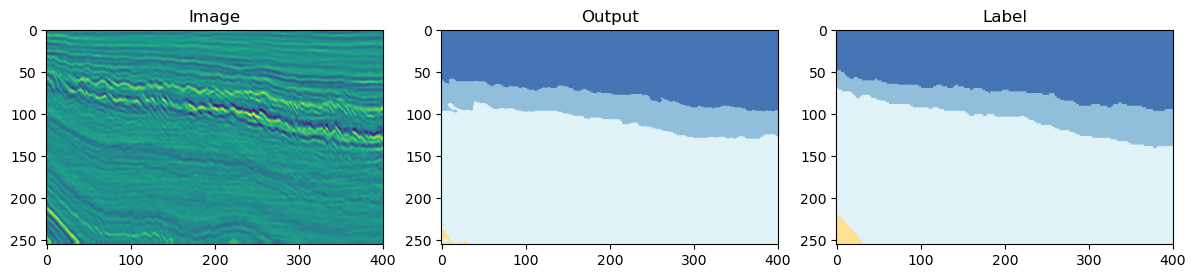

	Pixel Acc: 0.9591471552848816
	Class Accuracy: [0.99806809425354, 0.9040045738220215, 0.972380518913269, 0.5211833119392395, 0.7754109501838684, 0.0]
	Mean Class Acc: 0.6951746344566345
	Mean IoU: 0.5803444385528564
	Confusion Matrix: [[2102167.0, 4069.0, 0.0, 0.0, 0.0, 0.0], [66081.0, 768450.0, 15520.0, 0.0, 0.0, 0.0], [0.0, 111082.0, 3984089.0, 2082.0, 0.0, 0.0], [0.0, 24.0, 55627.0, 94133.0, 30830.0, 0.0], [0.0, 0.0, 0.0, 4249.0, 14670.0, 0.0], [0.0, 0.0, 0.0, 290.0, 6742.0, 0.0]]


  0%|          | 0/90 [00:00<?, ?batches/s]

TRAINING - Epoch: 3 | Loss: 42633.82610677083


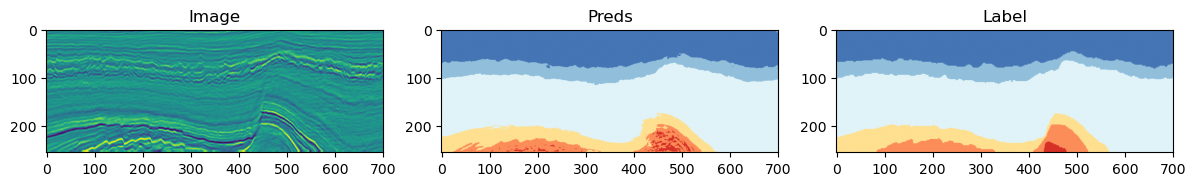

	Pixel Acc: 0.920401394367218
	Class Accuracy: [0.9712066054344177, 0.8980615735054016, 0.9554275274276733, 0.7947849631309509, 0.771303117275238, 0.06399831175804138]
	Mean Class Acc: 0.7424636483192444
	Mean IoU: 0.6407500505447388
	Confusion Matrix: [[17230946.0, 351499.0, 99184.0, 60163.0, 0.0, 0.0], [294876.0, 6734519.0, 390036.0, 72866.0, 6649.0, 4.0], [131870.0, 473130.0, 29701532.0, 702405.0, 74543.0, 3686.0], [19175.0, 49147.0, 466034.0, 3683291.0, 408316.0, 8361.0], [1556.0, 4080.0, 59768.0, 398478.0, 1812678.0, 73590.0], [0.0, 703.0, 13410.0, 163878.0, 794906.0, 66521.0]]
VALIDATION - Epoch: 3 | Loss: 386038.41654829547


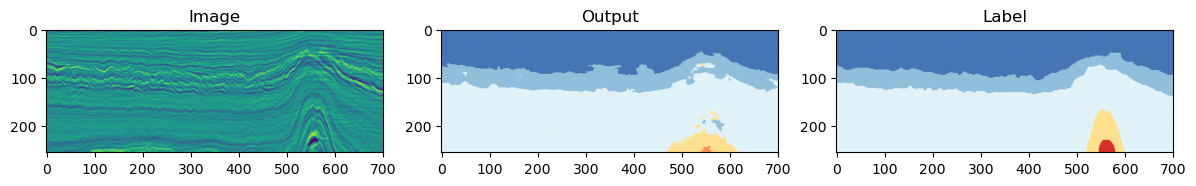

	Pixel Acc: 0.9353263974189758
	Class Accuracy: [0.9462135434150696, 0.886900007724762, 0.9693310856819153, 0.4221772253513336, nan, 2.3933751435833983e-05]
	Mean Class Acc: 0.6449291706085205
	Mean IoU: 0.4779985845088959
	Confusion Matrix: [[2267173.0, 128875.0, 0.0, 0.0, 0.0, 0.0], [21355.0, 905273.0, 92133.0, 1955.0, 0.0, 0.0], [4399.0, 65418.0, 3629132.0, 45003.0, 3.0, 0.0], [0.0, 1122.0, 69041.0, 53386.0, 2905.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 1261.0, 33187.0, 7333.0, 1.0]]


  0%|          | 0/90 [00:00<?, ?batches/s]

TRAINING - Epoch: 4 | Loss: 28369.589485677083


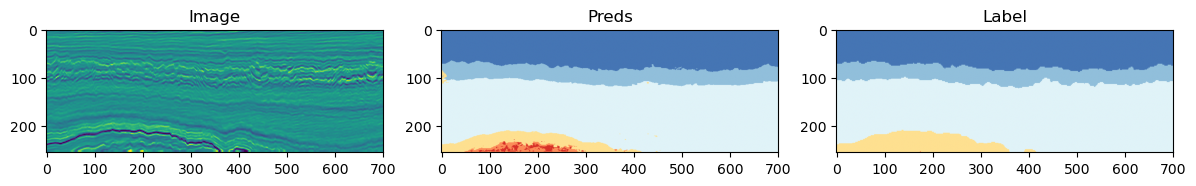

	Pixel Acc: 0.9422695636749268
	Class Accuracy: [0.9859580397605896, 0.9036679863929749, 0.9766184687614441, 0.8522623777389526, 0.7756500840187073, 0.22576479613780975]
	Mean Class Acc: 0.7866535782814026
	Mean IoU: 0.7007255554199219
	Confusion Matrix: [[17492660.0, 235417.0, 7453.0, 6222.0, 40.0, 0.0], [296179.0, 6776561.0, 383882.0, 39670.0, 2656.0, 2.0], [2781.0, 331978.0, 30360306.0, 337967.0, 52775.0, 1365.0], [12888.0, 62704.0, 239060.0, 3949660.0, 344369.0, 25643.0], [244.0, 2080.0, 26626.0, 328519.0, 1822894.0, 169787.0], [0.0, 116.0, 20034.0, 122762.0, 661842.0, 234664.0]]
VALIDATION - Epoch: 4 | Loss: 149793.92312282987


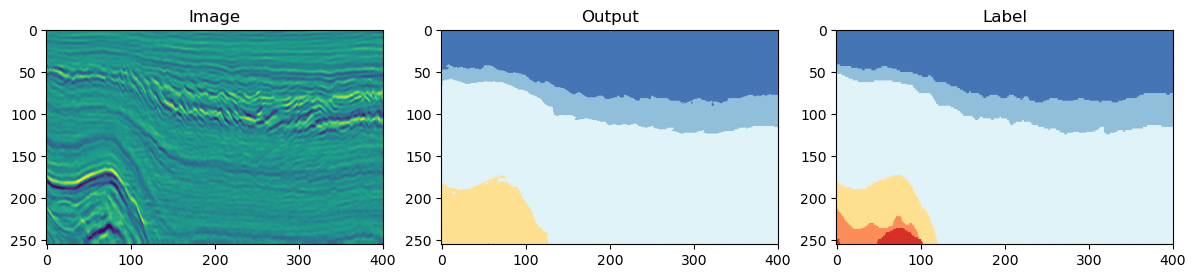

	Pixel Acc: 0.9749062657356262
	Class Accuracy: [0.9956462383270264, 0.9357238411903381, 0.9866586327552795, 0.7908689379692078, 0.0, 0.0015642775688320398]
	Mean Class Acc: 0.6184102892875671
	Mean IoU: 0.5855184197425842
	Confusion Matrix: [[2097066.0, 9170.0, 0.0, 0.0, 0.0, 0.0], [40181.0, 795413.0, 14419.0, 38.0, 0.0, 0.0], [0.0, 53203.0, 4042590.0, 1460.0, 0.0, 0.0], [0.0, 0.0, 37772.0, 142842.0, 0.0, 0.0], [0.0, 0.0, 505.0, 18414.0, 0.0, 0.0], [0.0, 0.0, 0.0, 6897.0, 124.0, 11.0]]


  0%|          | 0/90 [00:00<?, ?batches/s]

TRAINING - Epoch: 5 | Loss: 19703.386284722223


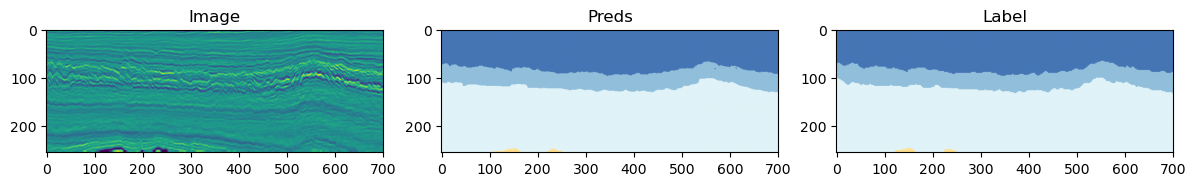

	Pixel Acc: 0.9578415751457214
	Class Accuracy: [0.9888978600502014, 0.9272655248641968, 0.9849262833595276, 0.9139013290405273, 0.7925162315368652, 0.40798985958099365]
	Mean Class Acc: 0.8359162211418152
	Mean IoU: 0.7606773376464844
	Confusion Matrix: [[17544816.0, 196250.0, 555.0, 169.0, 0.0, 0.0], [241766.0, 6953518.0, 298044.0, 5620.0, 2.0, 0.0], [6839.0, 280884.0, 30618568.0, 163691.0, 14287.0, 2897.0], [0.0, 2635.0, 141797.0, 4235315.0, 231872.0, 22705.0], [0.0, 8.0, 4173.0, 252571.0, 1862532.0, 230866.0], [0.0, 0.0, 1004.0, 64460.0, 549882.0, 424072.0]]
VALIDATION - Epoch: 5 | Loss: 183756.02911931818


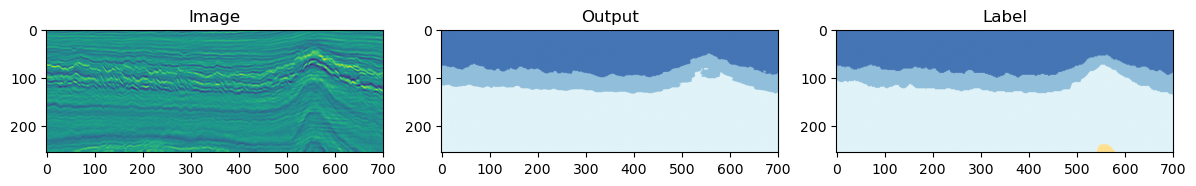

	Pixel Acc: 0.9621407389640808
	Class Accuracy: [0.9883044958114624, 0.9397197365760803, 0.9805724024772644, 0.3171350955963135, nan, 0.30998995900154114]
	Mean Class Acc: 0.7071443796157837
	Mean IoU: 0.5561612248420715
	Confusion Matrix: [[2368025.0, 28023.0, 0.0, 0.0, 0.0, 0.0], [28420.0, 959187.0, 33080.0, 29.0, 0.0, 0.0], [0.0, 58516.0, 3671219.0, 12567.0, 987.0, 666.0], [0.0, 241.0, 67579.0, 40103.0, 13751.0, 4780.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 1948.0, 11996.0, 14886.0, 12952.0]]


In [19]:
network, statistics = train_valid_stage(train_dataloader, valid_dataloader, criterion, optimizer, network, device=device, num_epochs=5, visual=True)

## Data Augmentation

Data augmentation é uma técnica usada para aumentar a quantidade e diversidade de dados de treinamento em aprendizado de máquina, principalmente no caso de imagens.  Imagine que você tem um número limitado de imagens para treinar seu modelo de reconhecimento facial. Através da data augmentation, você cria variações artificiais dessas imagens originais para "enganar" o modelo e torná-lo mais robusto.

Veja como funciona:
* Aplicando transformações geométricas: Você pode rotacionar, escalar, recortar e aplicar espelhamento nas imagens originais. Por exemplo, rotacionar uma imagem de rosto ligeiramente para a esquerda ou direita cria uma nova imagem que o modelo nunca viu antes, mas que ainda representa um rosto.
* Ajustando o brilho e contraste: Aumentando ou diminuindo o brilho e contraste das imagens, simula diferentes condições de iluminação nas quais o modelo pode precisar funcionar.
* Simulando oclusões: Introduzindo pequenas obstruções aleatórias nas imagens, como óculos escuros ou cabelo na frente do rosto, o modelo aprende a lidar com situações do mundo real onde a visão pode ser parcialmente bloqueada.

Veja alguns benefícios do data augmentation:
* Evita overfitting: Quando um modelo treina somente em dados muito específicos, ele pode se tornar muito bom em identificar aqueles dados, mas ter um péssimo desempenho em dados ligeiramente diferentes. A data augmentation ajuda a prevenir isso, expondo o modelo a uma maior variedade de cenários.
* Melhora a generalização: O objetivo final é que o modelo funcione bem em dados novos e nunca vistos antes. A data augmentation ajuda o modelo a aprender características gerais que se aplicam a um tipo de dado, em vez de memorizar detalhes específicos dos dados de treinamento.
* Reduz a necessidade de coleta de dados: Coletar grandes quantidades de dados rotulados pode ser caro e demorado. A data augmentation permite que você aproveite ao máximo os dados que já possui.



In [20]:
# https://pytorch.org/vision/0.9/transforms.html

class Compose(object):
    def __init__(self, augmentations):
        self.augmentations = augmentations

    def __call__(self, img, mask):
        mask = PIL.Image.fromarray(mask, mode='L')
        if len(img.shape) == 2:
            img = PIL.Image.fromarray(img, mode=None)
            assert img.size == mask.size
            for a in self.augmentations:
                img, mask = a(img, mask)
            return numpy.array(img), numpy.array(mask, dtype=numpy.uint8)
        elif len(img.shape) == 3:
            img = PIL.Image.fromarray(img.transpose(1,2,0), mode='RGB')
            assert img.size == mask.size
            for a in self.augmentations:
                img, mask = a(img, mask)
            return numpy.array(img).transpose(2,0,1), numpy.array(mask, dtype=numpy.uint8)
        else:
            raise RuntimeError(f'There is no implementation for image dimension {img.shape}')


class AddNoise(object):
    def __call__(self, img, mask):
        if img.im.bands == 1:
            noise = numpy.random.normal(loc=0,scale=0.02,size=(img.size[1], img.size[0]))
        else:
            noise = numpy.random.normal(loc=0,scale=0.02,size=(img.size[1], img.size[0], img.im.bands))
        return img + noise, mask


class RandomRotate(object):
    def __init__(self, degree=5.):
        self.degree = degree
        # self.counter = 0

    def __call__(self, img, mask):
        '''
        PIL automatically adds zeros to the borders of images that rotated. To fix this
        issue, the code in the botton sets anywhere in the labels (mask) that is zero to
        255 (the value used for ignore_index).
        '''
        rotate_degree = random.random() * 2 * self.degree - self.degree

        img = img.rotate(rotate_degree, PIL.Image.BILINEAR)
        mask =  mask.rotate(rotate_degree, PIL.Image.NEAREST)

        binary_mask = PIL.Image.fromarray(numpy.ones([mask.size[1], mask.size[0]]))
        binary_mask = binary_mask.rotate(rotate_degree, PIL.Image.NEAREST)
        binary_mask = numpy.array(binary_mask)

        mask_arr = numpy.array(mask)
        mask_arr[binary_mask==0] = 255
        mask = PIL.Image.fromarray(mask_arr)

        return img, mask


class RandomVerticallyFlip(object):
    def __call__(self, img, mask):
        if random.random() < 0.5:
            return img.transpose(PIL.Image.FLIP_LEFT_RIGHT), mask.transpose(PIL.Image.FLIP_LEFT_RIGHT)
        return img, mask

## Exercício 4

Retreine sua rede utilizando *data augmentation* e o otimizador `torch.optim.Adam`.

Houve alguma mudança nos resultados? E no tempo de convergência da rede?

In [21]:
data_aug = Compose([RandomRotate(degree=10), RandomVerticallyFlip(), AddNoise()])

train_dataset = F3BlockDataset(split='train', subset=train_subset, channel_delta=0, data_folder=data_path, is_transform=True, augmentations=data_aug)
valid_dataset = F3BlockDataset(split='valid', subset=valid_subset, channel_delta=0, data_folder=data_path, is_transform=True, augmentations=data_aug)

train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=4, sampler=CustomSampler(train_subset), num_workers=0, shuffle=False)
valid_dataloader = torch.utils.data.DataLoader(valid_dataset, batch_size=4, sampler=CustomSampler(valid_subset), num_workers=0)

  0%|          | 0/90 [00:00<?, ?batches/s]

TRAINING - Epoch: 1 | Loss: 107440.94435763889


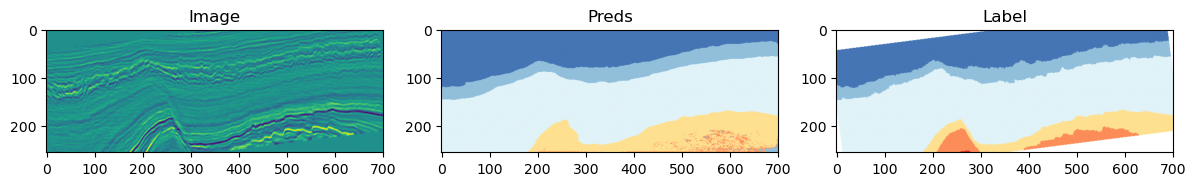

	Pixel Acc: 0.8503007292747498
	Class Accuracy: [0.963647723197937, 0.7887037992477417, 0.8911469578742981, 0.7983331084251404, 0.007845806889235973, 0.013871769420802593]
	Mean Class Acc: 0.5772581696510315
	Mean IoU: 0.465753436088562
	Confusion Matrix: [[15121673.0, 356954.0, 67040.0, 54001.0, 27901.0, 64548.0], [1069194.0, 5895225.0, 219789.0, 194689.0, 25350.0, 70327.0], [1624710.0, 695000.0, 26891590.0, 662929.0, 106742.0, 195409.0], [204597.0, 297408.0, 246448.0, 3250173.0, 24038.0, 48535.0], [87724.0, 264994.0, 28411.0, 1501266.0, 15074.0, 23812.0], [55414.0, 114168.0, 27665.0, 641795.0, 10612.0, 11952.0]]
VALIDATION - Epoch: 1 | Loss: 951351.1342329546


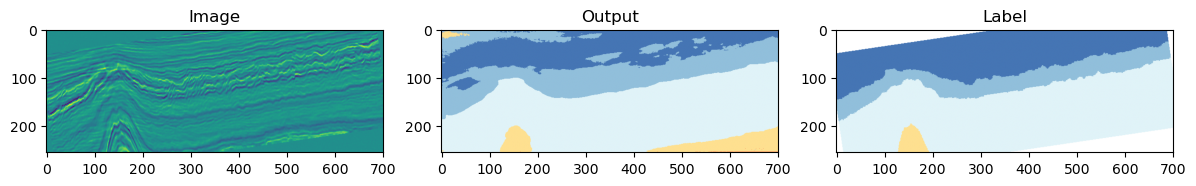

	Pixel Acc: 0.9030201435089111
	Class Accuracy: [0.7699663639068604, 0.9695362448692322, 0.985114574432373, 0.5216839909553528, nan, 0.0]
	Mean Class Acc: 0.6492602229118347
	Mean IoU: 0.45559513568878174
	Confusion Matrix: [[1656210.0, 494506.0, 0.0, 234.0, 66.0, 0.0], [4217.0, 988831.0, 26844.0, 8.0, 1.0, 0.0], [3.0, 39966.0, 3473184.0, 12508.0, 4.0, 0.0], [0.0, 0.0, 51226.0, 55924.0, 49.0, 0.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [1.0, 7.0, 31.0, 33188.0, 214.0, 0.0]]


  0%|          | 0/90 [00:00<?, ?batches/s]

TRAINING - Epoch: 2 | Loss: 39848.41516927083


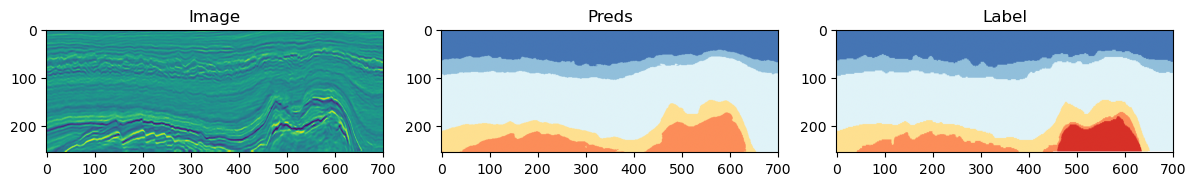

	Pixel Acc: 0.9514227509498596
	Class Accuracy: [0.9855654239654541, 0.9426499009132385, 0.9859920144081116, 0.9468051195144653, 0.611015796661377, 5.355718531063758e-05]
	Mean Class Acc: 0.7453469634056091
	Mean IoU: 0.6702768802642822
	Confusion Matrix: [[15608881.0, 226161.0, 2.0, 377.0, 2067.0, 0.0], [228791.0, 7048162.0, 195018.0, 2171.0, 2825.0, 0.0], [3260.0, 267250.0, 29731632.0, 143222.0, 8667.0, 0.0], [767.0, 5546.0, 99109.0, 3942488.0, 116081.0, 0.0], [2960.0, 14860.0, 16086.0, 744478.0, 1222697.0, 8.0], [8933.0, 9188.0, 20931.0, 192155.0, 627642.0, 46.0]]
VALIDATION - Epoch: 2 | Loss: 211425.13519965278


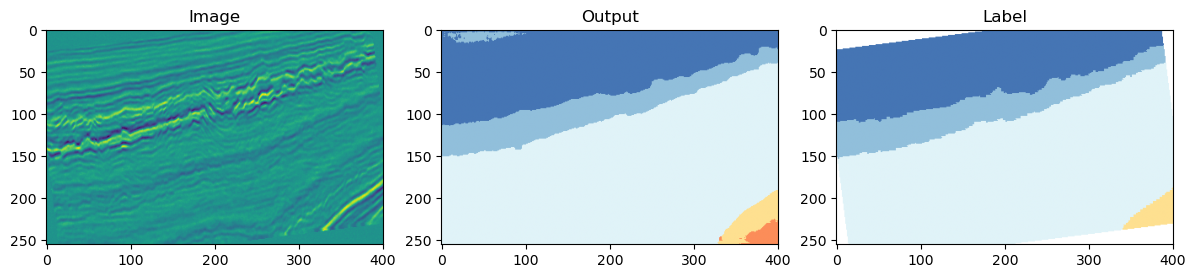

	Pixel Acc: 0.9829880595207214
	Class Accuracy: [0.9952877163887024, 0.9425474405288696, 0.9915317893028259, 0.8519789576530457, 0.8768391013145447, 0.0]
	Mean Class Acc: 0.7763641476631165
	Mean IoU: 0.6699759364128113
	Confusion Matrix: [[1941020.0, 9186.0, 0.0, 0.0, 4.0, 0.0], [38850.0, 796479.0, 9699.0, 0.0, 0.0, 0.0], [0.0, 32414.0, 3942018.0, 1011.0, 242.0, 0.0], [0.0, 0.0, 7553.0, 122161.0, 13669.0, 2.0], [0.0, 0.0, 0.0, 1264.0, 8999.0, 0.0], [0.0, 0.0, 0.0, 19.0, 3955.0, 0.0]]


  0%|          | 0/90 [00:00<?, ?batches/s]

TRAINING - Epoch: 3 | Loss: 23482.88025173611


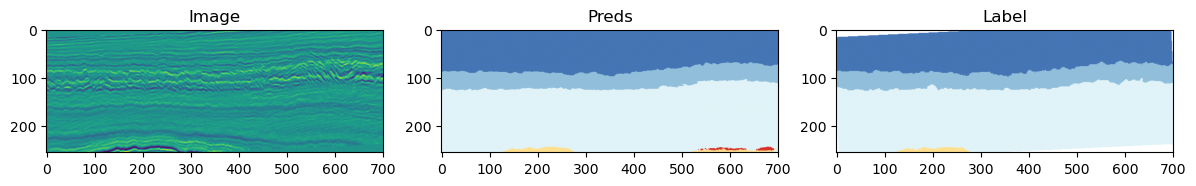

	Pixel Acc: 0.9696121215820312
	Class Accuracy: [0.9894010424613953, 0.9489101767539978, 0.9894703030586243, 0.9544386863708496, 0.9089921116828918, 0.29438626766204834]
	Mean Class Acc: 0.8475998044013977
	Mean IoU: 0.7861449122428894
	Confusion Matrix: [[15531593.0, 164543.0, 0.0, 0.0, 1835.0, 4.0], [179637.0, 7092479.0, 200569.0, 344.0, 500.0, 813.0], [732.0, 222102.0, 29812228.0, 87506.0, 6012.0, 902.0], [228.0, 52.0, 76466.0, 3922030.0, 109914.0, 563.0], [7444.0, 201.0, 597.0, 146153.0, 1770144.0, 22831.0], [11234.0, 5.0, 4112.0, 9032.0, 575268.0, 250178.0]]
VALIDATION - Epoch: 3 | Loss: 218794.31285511365


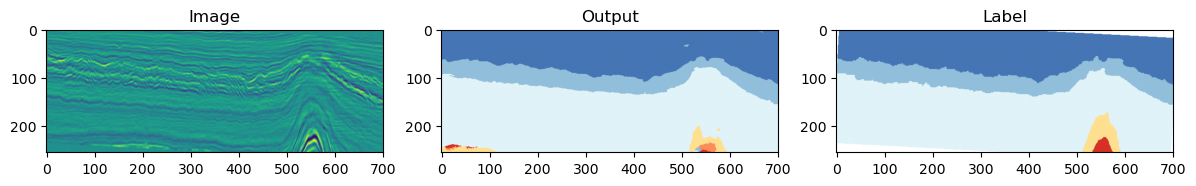

	Pixel Acc: 0.9658178091049194
	Class Accuracy: [0.9856143593788147, 0.9331387281417847, 0.9835906028747559, 0.533118486404419, nan, 0.2318420559167862]
	Mean Class Acc: 0.7334608435630798
	Mean IoU: 0.5816634297370911
	Confusion Matrix: [[2156127.0, 31470.0, 0.0, 0.0, 0.0, 0.0], [22598.0, 951753.0, 45597.0, 0.0, 0.0, 0.0], [2986.0, 49212.0, 3498442.0, 5771.0, 88.0, 308.0], [0.0, 4210.0, 45586.0, 60220.0, 2614.0, 328.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 5402.0, 3971.0, 8566.0, 7507.0, 7680.0]]


  0%|          | 0/90 [00:00<?, ?batches/s]

TRAINING - Epoch: 4 | Loss: 25584.320008680555


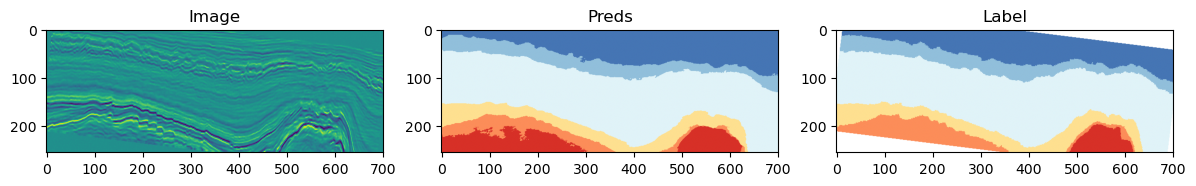

	Pixel Acc: 0.9567630290985107
	Class Accuracy: [0.9802243709564209, 0.9241685271263123, 0.9830781817436218, 0.8860387802124023, 0.7539927959442139, 0.6910945773124695]
	Mean Class Acc: 0.8697662353515625
	Mean IoU: 0.7870340347290039
	Confusion Matrix: [[15430360.0, 283660.0, 24606.0, 1202.0, 316.0, 1517.0], [285537.0, 6908584.0, 264365.0, 6325.0, 7370.0, 3278.0], [5952.0, 278086.0, 29635126.0, 198236.0, 13081.0, 14757.0], [978.0, 5749.0, 157571.0, 3633318.0, 294611.0, 8404.0], [116.0, 6347.0, 7759.0, 286136.0, 1488792.0, 185394.0], [8.0, 5941.0, 16980.0, 24656.0, 218158.0, 594530.0]]
VALIDATION - Epoch: 4 | Loss: 136481.9080041956


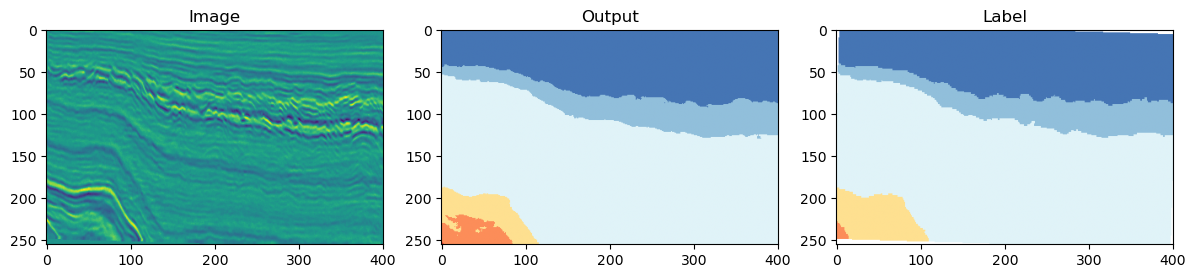

	Pixel Acc: 0.9805041551589966
	Class Accuracy: [0.9858191013336182, 0.9531413912773132, 0.9900120496749878, 0.8289994597434998, 0.8399410247802734, 0.8432654738426208]
	Mean Class Acc: 0.9068631529808044
	Mean IoU: 0.7405770421028137
	Confusion Matrix: [[1939605.0, 27901.0, 0.0, 0.0, 0.0, 0.0], [23829.0, 806451.0, 15722.0, 0.0, 0.0, 96.0], [755.0, 25457.0, 3947189.0, 12599.0, 43.0, 968.0], [0.0, 0.0, 1813.0, 123506.0, 23181.0, 482.0], [0.0, 0.0, 0.0, 427.0, 11398.0, 1745.0], [0.0, 0.0, 0.0, 31.0, 808.0, 4514.0]]


  0%|          | 0/90 [00:00<?, ?batches/s]

TRAINING - Epoch: 5 | Loss: 15871.555946180555


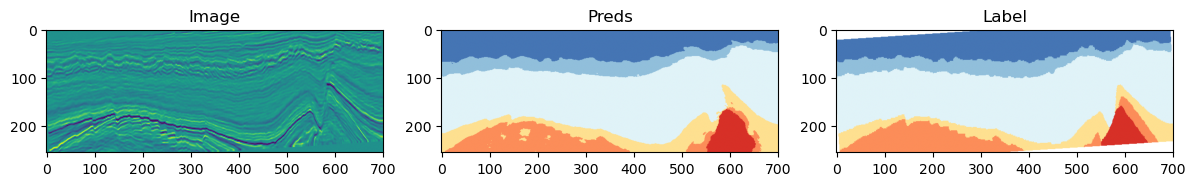

	Pixel Acc: 0.9744296073913574
	Class Accuracy: [0.9885730743408203, 0.9440233707427979, 0.9891721606254578, 0.940320611000061, 0.8654417991638184, 0.8719947934150696]
	Mean Class Acc: 0.9332542419433594
	Mean IoU: 0.8793463706970215
	Confusion Matrix: [[15609111.0, 178660.0, 179.0, 38.0, 787.0, 762.0], [200384.0, 7057501.0, 217539.0, 165.0, 185.0, 207.0], [485.0, 220982.0, 29898484.0, 103296.0, 1495.0, 1023.0], [155.0, 519.0, 98248.0, 3828806.0, 134974.0, 9107.0], [267.0, 1300.0, 1538.0, 151698.0, 1669722.0, 104804.0], [4.0, 64.0, 450.0, 15043.0, 99966.0, 786991.0]]
VALIDATION - Epoch: 5 | Loss: 155002.005859375


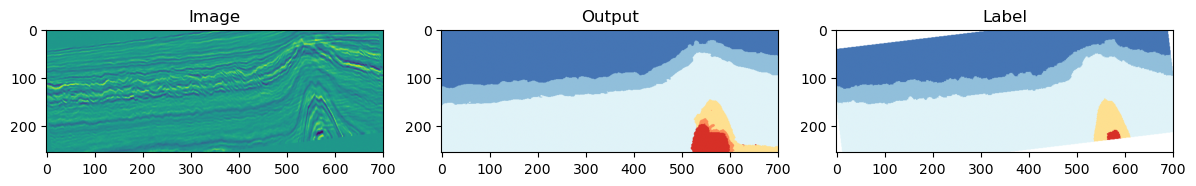

	Pixel Acc: 0.9608812928199768
	Class Accuracy: [0.9893869757652283, 0.9347917437553406, 0.9771613478660583, 0.3111865520477295, nan, 0.23220428824424744]
	Mean Class Acc: 0.6889461874961853
	Mean IoU: 0.5362663865089417
	Confusion Matrix: [[2119162.0, 22732.0, 0.0, 0.0, 0.0, 0.0], [28859.0, 953338.0, 32585.0, 1183.0, 2699.0, 1176.0], [3773.0, 51662.0, 3438918.0, 5794.0, 9211.0, 9936.0], [0.0, 0.0, 61819.0, 34102.0, 8649.0, 5017.0], [0.0, 0.0, 0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 492.0, 8531.0, 12625.0, 6547.0]]


In [22]:
network = DeconvNet(n_channels=1, n_classes=train_dataset.n_classes).to(device)
criterion = CrossEntropyLoss(reduction='sum', weight=None)
optimizer = torch.optim.Adam(network.parameters(), lr=3e-4, amsgrad=True)

torch.cuda.empty_cache()

network, statistics = train_valid_stage(train_dataloader, valid_dataloader, criterion, optimizer, network, device=device, num_epochs=5, visual=True)

## Desafio

Até agora, você implementou o treinamento e validação utilizando exclusivamente o bloco de treinamento. Está na hora de verificar a acurácia de seu método nos conjuntos de testes. Entretanto, desta vez, você poderá utilizar artifícios como data augmentation e, até mesmo, três canais na entrada de sua rede.

Implemente a predição em um dos conjuntos de teste da base de dados *F3 Block* (*test1* ou *test2*).